<table border=0 width="100%"><tr><td><p align="left"><font size=5><B>数据分析与可视化</B></font></p></td><td><font size=3><B>Numpy - pandas - plt(郑海超)</B></font></td></tr></table>

# 内容
- numpy数组和list的区别
- numpy数组基础操作:以Titanic为例
- numpy数组基础操作:以图片翻转为例
- 预处理与数据可视化：以股吧数据预处理为例

# 大脑的可塑性与自我调控能力的重要性

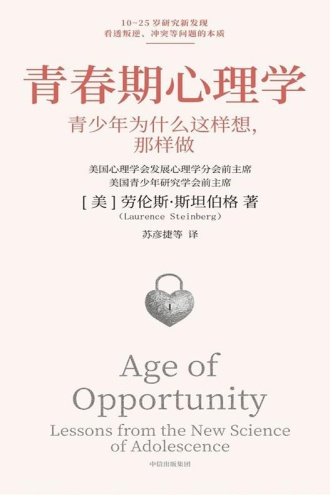

# numpy数组和list的区别

**NumPy（Numerical Python的简称）**是Python数值计算最重要的基础包。大多数提供科学计算的包都是用NumPy的数组作为构建基础。

NumPy的部分功能如下:
* ndarray，一个具有矢量算术运算和复杂***广播***能力的快速且节省空间的<font color=blue>多维数组</font>。
* 用于对***整组数据***进行快速运算的标准数学函数（无需编写循环）。
* 线性代数、随机数生成以及傅里叶变换功能。
* 用于集成由C、C++、Fortran等语言编写的代码的API。

NumPy对于数值计算特别重要的原因之一，是因为它可以***高效处理大数组的数据***。这是因为：
* NumPy是在一个连续的内存块中存储数据，独立于其他Python内置对象。NumPy的C语言编写的算法库可以操作内存，而不必进行类型检查或其它前期工作。比起Python的内置序列，NumPy数组使用的内存更少。
* NumPy可以在整个数组上执行复杂的计算，而***不需要Python的for循环***。

在实现层面，数组本质上包含一个指向一个连续数据块的指针。而Python列表包含一个指向指针块的指针，每个指针又指向一个完整的Python对象。如下图所示：

<img src="../../pic/array.png" align='left' height="350" width="400"/>

In [2]:
# 考察一个包含一百万整数的数组，和一个等价的Python列表：
import numpy as np
my_arr = np.arange(1000000)
my_list = list(range(1000000))      

魔法命令
- %time
- %%time

In [ ]:
# 计时 %time
for _ in range(10): my_arr2 = my_arr * 2 # 每个元素乘以2

1s = 1000ms

CPU time：衡量的是CPU用来执行程序的时间；

Wall time：从计算开始到计算结束等待的时间。

**如何对列表的每个元素乘以2？**

In [ ]:
# my_list * 2是什么操作？
my_list * 2

In [ ]:
for _ in range(10): my_list2 = [x * 2 for x in my_list] # 列表每个元素乘以2

**大家可以调整一下数组或者列表的长度体验一下二者的差异**

# numpy数组基础操作:以Titanic为例

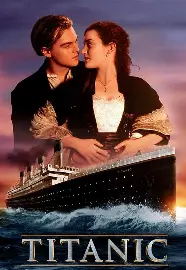

### 导入数据并探索数据属性

the columns of titanic.csv

| index | column name |
| ------ | ------ | 
| 0 | Survived | 
| 1 | Pclass | 
| 2 | Name | 
| 3 | Sex | 
| 4 | Age | 
| 5 | Siblings | 
| 6 | Parents | 
| 7 | Fare |  

[Kaggle](https://www.kaggle.com/c/titanic/data)

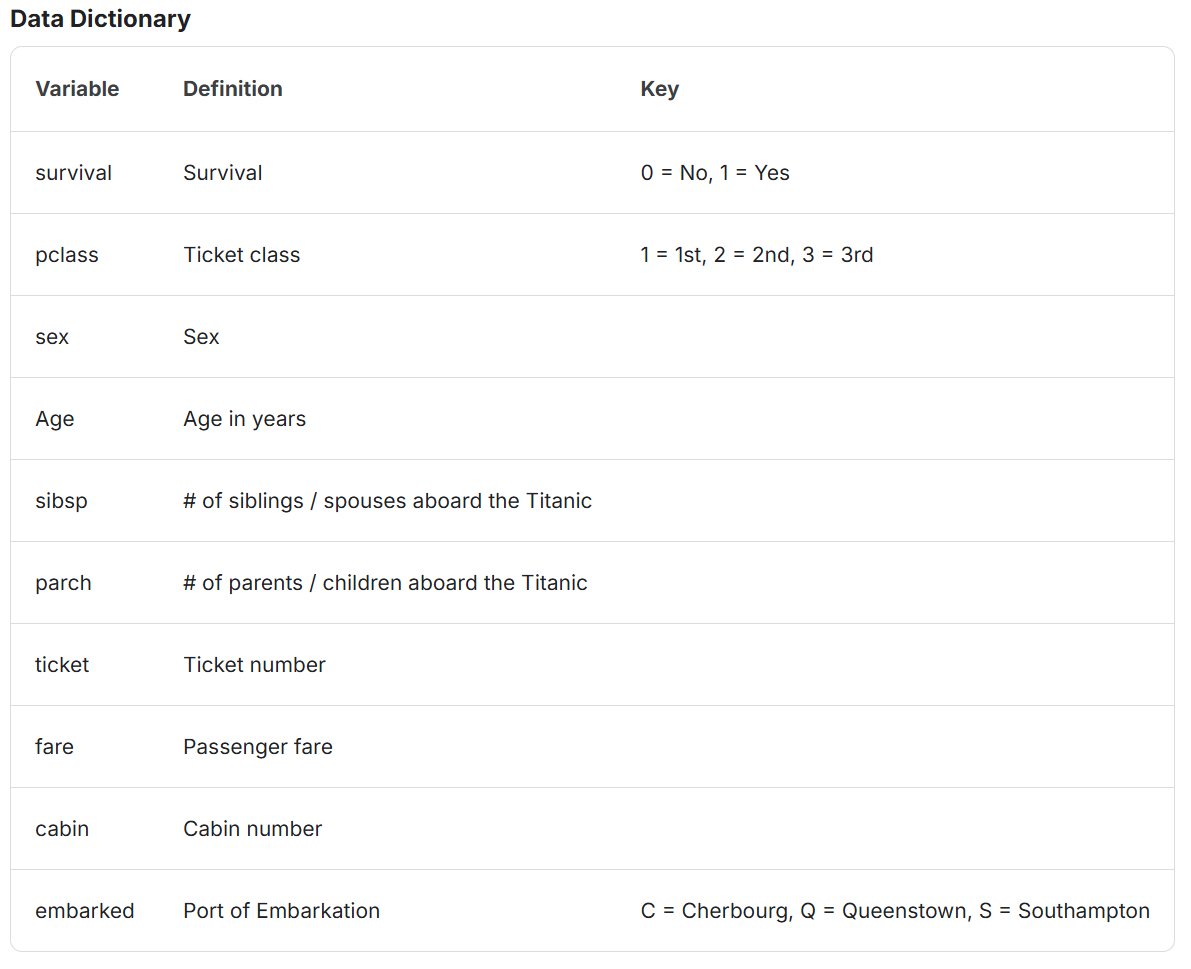

In [4]:
# read numpy from csv file
titanic = "titanic.csv"
titanic_data = np.loadtxt(titanic,delimiter=",",skiprows= 1,dtype=str)
# titanic_data = np.loadtxt(titanic,delimiter=",",skiprows= 1,usecols=(0,1,3,4,7),dtype=str)

In [11]:
# Q1: how many passengers in the ship?
print("Q1", titanic_data.shape[0])

# Q2: what is the data type of the dataset?
print("Q2", titanic_data.dtype)

# Q3: how many entries in the dataset?
print("Q3", titanic_data.size)

# Q4: how many dimensions of the array?
print("Q4", titanic_data.ndim)

# Q5: ratios of survivors and non-survivors for women and men
women = titanic_data[titanic_data[:, 3] == "female", 0]
men = titanic_data[titanic_data[:, 3] == "male", 0]
print("women", (women == "1").mean())
print("men", (men == "1").mean())


Q1 887
Q2 <U81
Q3 7096
Q4 2
women 0.7420382165605095
men 0.19022687609075042


### numpy数组相乘

## np.dot

这种运算在机器学习的数据转换中很常用，例如神经网络的全连接网络。

<img src="../../pic/dot.png" align='left' height="300" width="400"/>

In [12]:
# np.dot
a = np.array([1,1,1])
b = np.array([1,2,3])

print(a * b)

print(np.dot(a,b))


[1 2 3]
6


In [13]:
x = np.array([1,2])
W = np.array([[1,3,5],
             [2,4,6]])
print(x.shape)
print(W.shape)
print(np.dot(x,W))

(2,)
(2, 3)
[ 5 11 17]


In [ ]:
x = np.array([[1,2],
              [1,1]])
W = np.array([[1,3,5],
             [2,4,6]])
print(x.shape)
print(W.shape)
print(np.dot(x,W))

## 矩阵乘法和神经元网络构造

https://zh.d2l.ai/chapter_multilayer-perceptrons/mlp.html

一个单隐藏层的多层感知机，具有5个隐藏单元
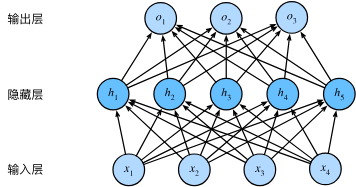

下面是一个更简单的神经网络，没有任何中间层（隐藏层）

<img src="../../pic/matrix_multiply.png" align='left'/>

Matrix multiplication is often used in the linear transformation step. Let's say we have an input vector x of size n, and we want to transform it using a weight matrix W of size m x n, where m is the number of neurons in the current layer. We can do this by computing the dot product of the weight matrix and the input vector:

z = Wx

This gives us a new vector z of size m. We can then apply an activation function to z to get the output of the current layer. For example, if we use the ReLU activation function, the output y would be:

y = max(0, z) （在神经网络中，我们会将z称为神经元的输出，将y称为神经元的激活值）

In [14]:
import numpy as np

# Define the input vector and weight matrix
x = np.array([1, -2, 3])
W = np.array([[0.1, 0.2, 0.3], [0.4, -0.5, 0.6], [-0.7, -0.8, 0.9], [1.0, -1.1, -1.2]])

# Compute the dot product to get the output vector
z = np.dot(W, x)

z


array([ 0.6,  3.2,  3.6, -0.4])

In [ ]:
# Apply the ReLU activation function to the output vector
y = np.maximum(0, z)

Questions: explain the code above, and how it performs the feedforward process in a neural network.

tips: compute that transformaiton by hand

# numpy数组基础操作:以图形变形为例

(357, 357, 3)
<class 'numpy.ndarray'>


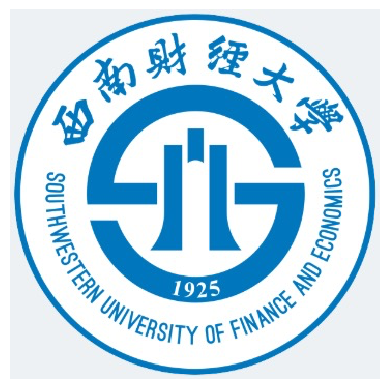

In [17]:
from numpy._typing._shape import _AnyShape


from numpy import dtype


from typing import Any


import numpy as np
import matplotlib.pylab as plt

def plti(im, **kwargs):
    """
    画图的辅助函数
    """
    plt.imshow(im, interpolation="none", **kwargs)
    plt.axis('off') # 去掉坐标轴
    plt.show() # 弹窗显示图像


# 加载图像
im = plt.imread("swufeLogo.png") # 加载图片
print(im.shape) # 输出图像尺寸
print(type[_AnyShape, dtype[Any]](im))
plti(im)

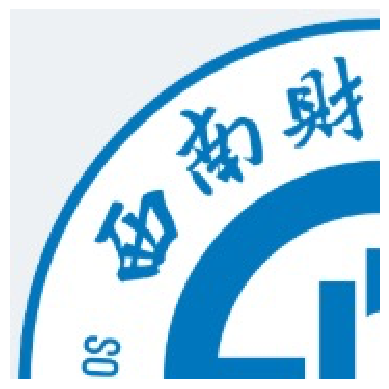

In [19]:
# 剪切图片(左上角)：行、列都取前一半
plti(im[: im.shape[0] // 2, : im.shape[1] // 2])


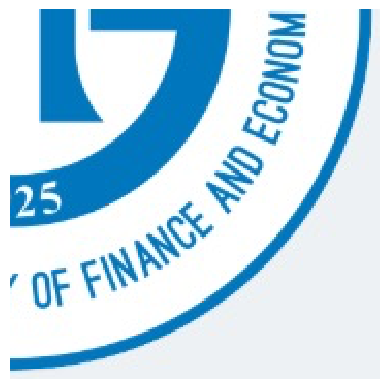

In [20]:
# 剪切图片(右下角)：行、列都从一半取到末尾
plti(im[im.shape[0] // 2 :, im.shape[1] // 2 :])


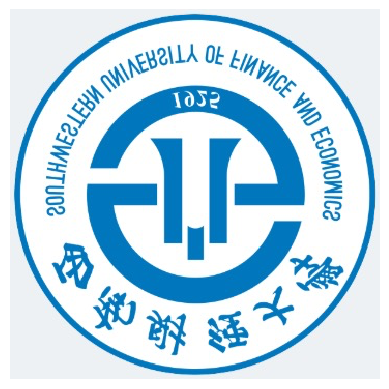

In [ ]:
# 图片上下翻转(调整步长试试呢)
# 第 0 维是行。步长 -1 表示从最后一行走到第一行
# 把 -1 改成 2，会隔一行取一次
# 这里只写了一段，等价于 im[::-1, :, :]
plti(im[::-1])


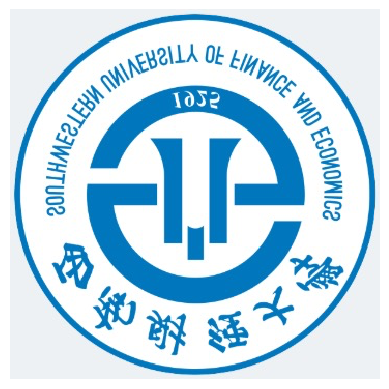

In [21]:
plti(im[::-1, :, :])

# 使用pandas预处理数据：以股吧数据为例

## 构建dataframe

In [ ]:
import pandas as pd

# 创建多个Series
series1 = pd.Series([1, 2, 3, 4])
series2 = pd.Series([5, 6, 7, 8])
series3 = pd.Series([9, 10, 11, 12])

# 使用序列构建dataframe
df = pd.DataFrame({"A":series1,"B": series2, "C":series3})

print(df)

## task
预处理东方财富股吧中[光线传媒相关的评论](http://guba.eastmoney.com/list,300251.html)。股评数据保存在data文件夹,数据文件是300251.csv。主要工作包括：
* 读取数据
* 修改数据类型
* 删除不需要的列
* 删除光线传媒发布的文章 

数据清洗是数据分析第一步重要工作，特别是我们从网络抓取的数据，更是需要特别谨慎。如果输入的是垃圾，那么得到的也是垃圾。作为数据分析人员，我们一定要敢于跳进数据中，干一些数据清洗的脏活累活。

<img src="../../pic/garbage_in.jpg" height="200" width="300" style="display:block"/>

<img src="../../pic/cleaning.png" height="300" width="400" style="display:block"/>

## read data from csv

- encoding
- names=["date","author","url","comment"]

In [6]:
import pandas as pd
comments = pd.read_csv("300251.csv", encoding="gbk", names = ["date","author","url","comment"])
comments.columns

Index(['date', 'author', 'url', 'comment'], dtype='str')

In [7]:
comments.head()

,date,author,url,comment
0,2019-03-25 16:13:22,光线传媒资讯,"http://guba.eastmoney.com/news,300251,81164281...",\r\n 光线传媒:关...
1,2019-03-26 15:47:21,恭喜发财红利就来,"http://guba.eastmoney.com/news,300251,81192614...",\r\n 各位兄弟，再...
2,2019-03-26 16:18:41,老老老老老康,"http://guba.eastmoney.com/news,300251,81193282...",\r\n 继续加仓了，...
3,2019-03-26 17:04:14,说你点啥好呢,"http://guba.eastmoney.com/news,300251,81194240...",\r\n 跌破8块可以...
4,2019-03-26 17:30:25,资金解密,"http://guba.eastmoney.com/news,300251,81194742...",\r\n 光线传媒03...


In [8]:
# 有多少独立的作者:unique()
len(comments["author"].unique())

20528

## 数据预处理任务

- 数据类型转换：将日期字符串转换为日期类型
- 对comments按日期排序，对比用和不用inplace=True， 不需要ascending=False
- drop column url from comments
- delete the comments posted by 光线传媒资讯
- drop the  comments longer than 1000 words

In [9]:
# 1. 数据类型转换：日期字符串 -> 日期类型
comments["date"] = pd.to_datetime(comments["date"])
comments.dtypes          # date 列变成 datetime64[ns]


date       datetime64[us]
author                str
url                   str
comment               str
dtype: object

In [10]:
# 2. 按日期排序：对比用和不用 inplace=True
comments.sort_values("date").head()          # 不接返回值：返回的新表被丢弃，原 comments 没变（白排）


,date,author,url,comment
107189,2011-07-14 21:30:36,NaN,"http://guba.eastmoney.com/news,300251,41042328...",\r\n 88888\...
77669,2011-07-14 21:31:46,NaN,"http://guba.eastmoney.com/news,300251,41042370...",\r\n 发行价30块...
107188,2011-07-14 21:33:20,NaN,"http://guba.eastmoney.com/news,300251,41042422...",\r\n 3\r\n ...
129105,2011-07-14 22:01:26,更深的蓝888,"http://guba.eastmoney.com/news,300251,41043504...",\r\n 好股，拿住！...
107192,2011-07-14 22:20:38,NaN,"http://guba.eastmoney.com/news,300251,41044269...",\r\n 应收账款与日...


In [11]:
comments = comments.sort_values("date")      # 不用 inplace 的正确写法：必须接住返回值
comments.head()                             # 已按日期升序（默认 ascending=True，无需指定）


,date,author,url,comment
107189,2011-07-14 21:30:36,NaN,"http://guba.eastmoney.com/news,300251,41042328...",\r\n 88888\...
77669,2011-07-14 21:31:46,NaN,"http://guba.eastmoney.com/news,300251,41042370...",\r\n 发行价30块...
107188,2011-07-14 21:33:20,NaN,"http://guba.eastmoney.com/news,300251,41042422...",\r\n 3\r\n ...
129105,2011-07-14 22:01:26,更深的蓝888,"http://guba.eastmoney.com/news,300251,41043504...",\r\n 好股，拿住！...
107192,2011-07-14 22:20:38,NaN,"http://guba.eastmoney.com/news,300251,41044269...",\r\n 应收账款与日...


In [12]:
comments.sort_values("date", inplace=True)   # 用 inplace：原地修改，返回 None，不能再赋值回去
comments.head()


,date,author,url,comment
107189,2011-07-14 21:30:36,NaN,"http://guba.eastmoney.com/news,300251,41042328...",\r\n 88888\...
77669,2011-07-14 21:31:46,NaN,"http://guba.eastmoney.com/news,300251,41042370...",\r\n 发行价30块...
107188,2011-07-14 21:33:20,NaN,"http://guba.eastmoney.com/news,300251,41042422...",\r\n 3\r\n ...
129105,2011-07-14 22:01:26,更深的蓝888,"http://guba.eastmoney.com/news,300251,41043504...",\r\n 好股，拿住！...
107192,2011-07-14 22:20:38,NaN,"http://guba.eastmoney.com/news,300251,41044269...",\r\n 应收账款与日...


In [13]:
# 3. drop url 列（axis=1 表示按列删；两种写法二选一）
comments = comments.drop("url", axis=1)           # 写法一：接住返回值
comments.head()


,date,author,comment
107189,2011-07-14 21:30:36,NaN,\r\n 88888\...
77669,2011-07-14 21:31:46,NaN,\r\n 发行价30块...
107188,2011-07-14 21:33:20,NaN,\r\n 3\r\n ...
129105,2011-07-14 22:01:26,更深的蓝888,\r\n 好股，拿住！...
107192,2011-07-14 22:20:38,NaN,\r\n 应收账款与日...


In [14]:
# 4. 删除光线传媒资讯发布的评论（布尔索引：只留作者不是它的行）
comments = comments[comments["author"] != "光线传媒资讯"]
len(comments)   # 129856 -> 126074


126074

In [15]:
# 5. 删除超过 1000 字的评论（str.len() 逐条算长度）
comments = comments[comments["comment"].str.len() <= 1000]
len(comments)   # 126074 -> 124525


124942

## process date with pandas

下面这个步骤可能存在争议，不是必须：


下面我们汇总每天的评论数。首先需要调整日期：我国股市下午3点停盘。每天下午3点之后的评论被划到第二天，因此每天有效的评论时间段是前一天15:00到当天的15:00之前。要调整日期，需要学一下预备知识：Timestamp、Timedelta
* Timestamp是从Python标准库的datetime类继承过来的，表示时间轴上的一个时刻。
* Timedelta表示时间上差异，以差异单位表示，例天，小时，分钟，秒。

In [ ]:
#调用Timestamp()创建任意时间点
fool_day = pd.Timestamp('2025-11-19')
now = pd.Timestamp.now()
# Timestamp相减可以获得Timedelta对象
td = now - fool_day
# 通过days获得相差的天数
td

In [ ]:
# 也可以自己定义一个Timedelta对象
now = pd.Timestamp.now()
print (now)
td = pd.Timedelta("10 hour")
now_plus_tendays = now + td
print(now_plus_tendays)

In [ ]:
def modify_date(date_time):
    """
    调整日期，我国股市3点停盘。每天下午3点之后的评论调整为下一天的
    参数：
        date_time:评论的真实日期
    返回：
        date:调整后的日期
    """
    h = date_time.hour
    y = date_time.year
    m = date_time.month
    d = date_time.day
    date = pd.Timestamp(y,m,d)
    if h >= 15:
        date = date + pd.Timedelta("1 day")
    return date

In [ ]:
# 也可以自己定义一个Timedelta对象
now = pd.Timestamp.now()
print (now)
# add 8 hours to now
td = pd.Timedelta("8 hour")
now_plus_eighthour = now + td
print(now_plus_eighthour)


In [ ]:
modify_date(now_plus_eighthour)

使用apply或者map函数可以在一个序列上做运算， 输入的参数是一个函数，例如这里使用定义好的modify_date函数，对date列进行运算，返回修正后的日期序列。

In [ ]:
comments["modified_date"] =comments["date"].apply(modify_date)
comments.head(10)
# comments["date"].apply(modify_date)

## extract the hour, dayofweek, month of the date

In [18]:
# 提取hour，从comments.date.dt提取
comments["hour"] = comments["date"].dt.hourcomments.date.dt.hour


In [19]:
comments["hour"].unique()

array([21, 22,  8,  9, 12, 23, 10, 17, 18, 20,  2, 14, 16, 11, 13, 15, 19,
        4,  0,  3,  6,  7,  1,  5], dtype=int32)

In [ ]:
# 提取dayofweek, Monday=0, Sunday=6, 在comments.modified_date.dt提取，并且可以+1
comments["dayofweek"] = comments["modified_date"].dt.dayofweek + 1  # Monday=0,Sunday=6，+1后周一=1...周日=7comments["modified_date"].dt.dayofweek + 1


AttributeError: 'DataFrame' object has no attribute 'modified_date'

In [ ]:
comments.dayofweek.unique()

In [ ]:
# 提取month, 在comments.modified_date.dt提取
comments["month"] = comments["modified_date"].dt.month




In [ ]:
comments["month"].unique()

In [ ]:
comments.head()

## save dataframe to csv file

In [ ]:
# 按列切片多个列
saved_comments = comments[["date","modified_date","comment","author","hour","dayofweek","month"]]

# 按日期排序后保存到cleaned_300251_comments.csv
# saved_comments.sort_values(["date"]).to_csv("cleaned_300251_comments.csv")


In [ ]:
saved_comments.head(100)

# 探索评论数据的分布

## read csv file

In [ ]:
# index_col：Column(s) to use as the row labels
# usecols：Return a subset of the columns.
comments = pd.read_csv("cleaned_300251_comments.csv",
                      index_col=["date"],
                      parse_dates = ["date"],
                      usecols= ["modified_date","date","comment","author","hour","dayofweek","month"])

In [ ]:
comments.head(100)

## When do people make comments actively?
- 每天的哪

In [ ]:
# 通过value_counts函数获得序列中非重复元素的个数:comments.hour.value_counts()
hour_counts = comments["hour"].value_counts()




In [ ]:
# 对hour_counts的索引进行排序
hour_counts.sort_index(inplace=True)
#hour_counts

In [ ]:
# 绘制hour_counts的柱状图:plot(kind = "bar")
hour_counts.plot(kind = "bar")


In [ ]:
comments.head()

groupby

这里我们引入groupby函数来实现相似的功能。之前我们尝试使用max或mean函数对序列进行汇总，求最大值或均值，这些都是求全局汇总运算。然而，要更深入地研究数据，简单的聚合汇总通常是不够的。groupby操作允许您快速而有效地计算数据子集上的聚合。groupby聚合运算参见下图，参考资料《Python Data Science Handbook》，作者Jake VanderPlas。

<img src="../../pic/groupby.png" align='left' height="300" width="400"/>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
# I will load the data titanic.csv and assign it to variable titanic. 
titanic = pd.read_csv("titanic.csv")

In [ ]:
# group the data  titanic according to Pclass 
titanic_grouped = titanic.groupby("Pclass")

In [ ]:
# visulize the average survived rates for each class.
titanic_grouped["Survived"].mean().plot(kind = "bar")

In [ ]:
for (pclass,group) in titanic_grouped:
    print(pclass)
    print(type(group))
    print(group.values)

## which hour people make comments actively?

- use groupby function to group the data according to hour
- visulize the average number of comments for each hour
- which hour people make comments actively?

In [46]:
# Sort group keys. Groupby preserves the order of rows within each group.
comments_group_by_hour = comments.groupby(["hour"])
comments_group_by_hour

In [47]:
# The GroupBy object is a very flexible abstraction. 
# you can simply treat it as if it’s a collection of DataFrames
for (hour,group) in comments_group_by_hour:
    print(hour)
    print(group.shape)

(0,)
(1165, 6)
(1,)
(627, 6)
(2,)
(351, 6)
(3,)
(237, 6)
(4,)
(235, 6)
(5,)
(341, 6)
(6,)
(806, 6)
(7,)
(1561, 6)
(8,)
(3202, 6)
(9,)
(11891, 6)
(10,)
(18776, 6)
(11,)
(13338, 6)
(12,)
(5275, 6)
(13,)
(14596, 6)
(14,)
(16844, 6)
(15,)
(7097, 6)
(16,)
(4428, 6)
(17,)
(3536, 6)
(18,)
(3239, 6)
(19,)
(3338, 6)
(20,)
(3641, 6)
(21,)
(3755, 6)
(22,)
(3448, 6)
(23,)
(2399, 6)


In [48]:
# 对于分组的某个序列进行汇总预算，这里仅仅是计数：aggregate(np.count_nonzero)
import numpy as np
grouped_hour = comments_group_by_hour.aggregate(np.count_nonzero)
grouped_hour

,modified_date,comment,author,dayofweek,month
hour,,,,,
0,1165,1165,1165,1165,1165
1,627,627,627,627,627
2,351,351,351,351,351
3,237,237,237,237,237
4,235,235,235,235,235
5,341,341,341,341,341
6,806,806,806,806,806
7,1561,1561,1561,1561,1561
8,3202,3202,3202,3202,3202


<Axes: xlabel='hour'>

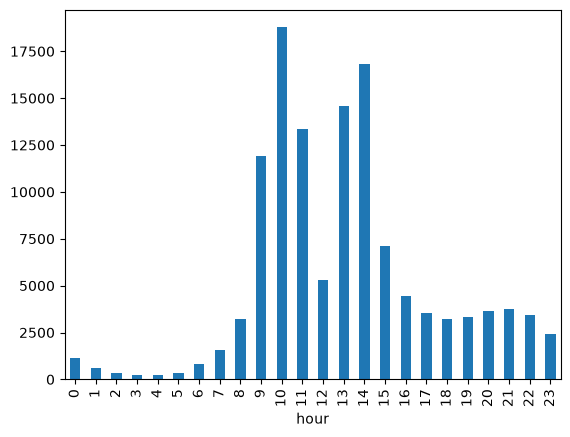

In [49]:
grouped_hour.comment.plot(kind="bar")

we can do it with groupby in another way

<Axes: xlabel='hour'>

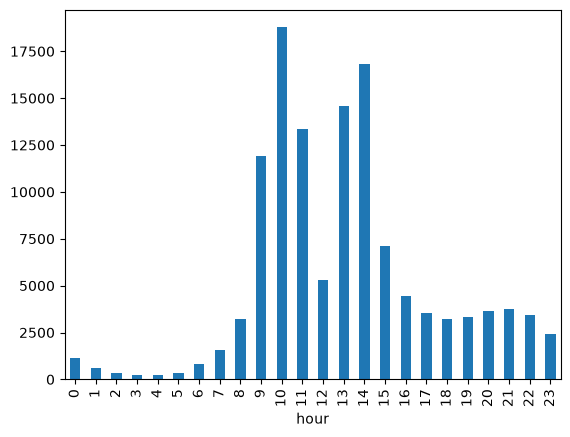

In [50]:
# group the comments by index date hour and counts each group
comments_by_hour = comments.groupby(["hour"])["hour"].count()
# plot comments_by_hour
comments_by_hour.plot(kind = "bar")

## group by dayofweek and hour

In [51]:
# 根据["dayofweek","hour"]进行分组, sort=True

comments_group_by_dayofweek_hour = comments.groupby(["dayofweek", "hour"], sort=True)

In [52]:
# 在分组内统计评论个数:aggregate(np.count_nonzero)
grouped_dayofweek_hour = comments_group_by_dayofweek_hour.aggregate(np.count_nonzero)
grouped_dayofweek_hour

modified_date  comment  author  month
dayofweek hour                                       
1         0               133      133     133    133
          1                75       75      75     75
          2                35       35      35     35
          3                23       23      23     23
          4                21       21      21     21
...                       ...      ...     ...    ...
7         19              283      283     283    283
          20              305      305     305    305
          21              359      359     359    359
          22              283      283     283    283
          23              250      250     250    250

[168 rows x 4 columns]

In [53]:
# 查看grouped_dayofweek_hour的index，这是MultiIndex
# unstack() 方法将DataFrame或Series中的索引级别"旋转"到列，从而改变数据的形状。它是 stack() 方法的逆操作。
grouped_dayofweek_hour.comment.unstack()

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dayofweek,,,,,,,,,,,,,,,,,,,,,
1,133,75,35,23,21,29,107,214,434,2382,...,3001,277,301,319,311,323,367,412,424,291
2,176,94,51,33,39,75,138,271,547,2029,...,3218,1279,806,606,540,570,682,631,537,390
3,159,97,47,42,54,59,132,270,546,2161,...,3238,1202,706,546,473,503,560,589,554,425
4,217,117,66,42,40,52,153,245,590,2263,...,3402,1346,802,618,607,597,617,646,622,359
5,181,91,79,45,40,69,131,293,621,2360,...,3368,1413,822,654,589,589,634,639,592,403
6,160,79,43,33,30,31,79,144,229,388,...,336,1246,688,548,461,473,476,479,436,281
7,139,74,30,19,11,26,66,124,235,308,...,281,334,303,245,258,283,305,359,283,250


In [54]:
# 使用unstack函数将最内层的行索引还原成了列索引
unstack_grouped_dayofweek_hour = grouped_dayofweek_hour.comment.unstack()
unstack_grouped_dayofweek_hour

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dayofweek,,,,,,,,,,,,,,,,,,,,,
1,133,75,35,23,21,29,107,214,434,2382,...,3001,277,301,319,311,323,367,412,424,291
2,176,94,51,33,39,75,138,271,547,2029,...,3218,1279,806,606,540,570,682,631,537,390
3,159,97,47,42,54,59,132,270,546,2161,...,3238,1202,706,546,473,503,560,589,554,425
4,217,117,66,42,40,52,153,245,590,2263,...,3402,1346,802,618,607,597,617,646,622,359
5,181,91,79,45,40,69,131,293,621,2360,...,3368,1413,822,654,589,589,634,639,592,403
6,160,79,43,33,30,31,79,144,229,388,...,336,1246,688,548,461,473,476,479,436,281
7,139,74,30,19,11,26,66,124,235,308,...,281,334,303,245,258,283,305,359,283,250


<Axes: xlabel='hour'>

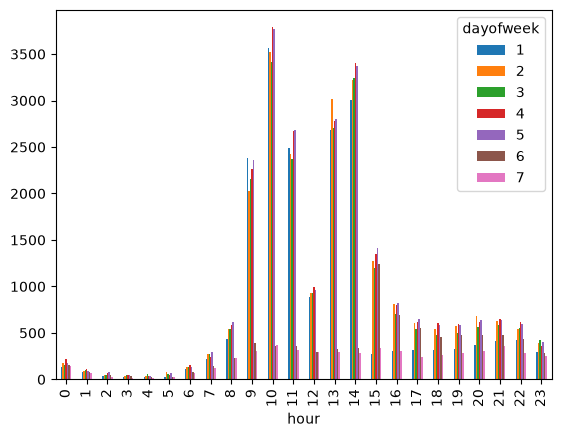

In [55]:
unstack_grouped_dayofweek_hour.T.plot(kind="bar")

In [56]:
import matplotlib.pyplot as plt
# IPython提供的一个有趣的后端是inline。有了这个后端，绘图命令的输出在前端显示，
# 就像Jupyter笔记本一样，直接显示在生成它的代码单元的下面。
%matplotlib inline

In [57]:
grouped_dayofweek_hour_unstack = grouped_dayofweek_hour.comment.unstack()
grouped_dayofweek_hour_unstack

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dayofweek,,,,,,,,,,,,,,,,,,,,,
1,133,75,35,23,21,29,107,214,434,2382,...,3001,277,301,319,311,323,367,412,424,291
2,176,94,51,33,39,75,138,271,547,2029,...,3218,1279,806,606,540,570,682,631,537,390
3,159,97,47,42,54,59,132,270,546,2161,...,3238,1202,706,546,473,503,560,589,554,425
4,217,117,66,42,40,52,153,245,590,2263,...,3402,1346,802,618,607,597,617,646,622,359
5,181,91,79,45,40,69,131,293,621,2360,...,3368,1413,822,654,589,589,634,639,592,403
6,160,79,43,33,30,31,79,144,229,388,...,336,1246,688,548,461,473,476,479,436,281
7,139,74,30,19,11,26,66,124,235,308,...,281,334,303,245,258,283,305,359,283,250


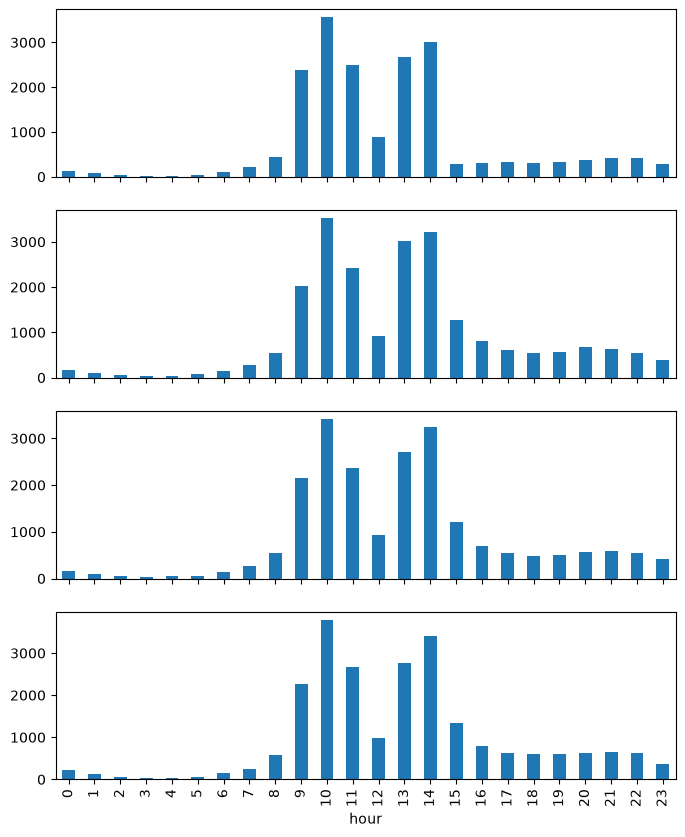

In [60]:
# 构建一个多子图，4行1列，共享x轴
fig, ax = plt.subplots(4, 1, sharex=True, figsize=(8, 10))

# 将周1-周6的评论数可视化：每个分组一行子图
# 数据里实际有 7 组（周一到周日），把 4 改成 7 可看全一周
for i in range(len(ax)):
    grouped_dayofweek_hour_unstack.iloc[i, :].plot(kind="bar", ax=ax[i])


<font color=blue face=雅黑>思考：大家分析上图能够发现什么规律呢？</font>